# Assignment: Supervised Learning – Regression

## Step 1: Data Exploration

**Objective:** Explore the used car dataset and understand the features that may influence selling prices.

In [2]:

from google.colab import files

uploaded = files.upload()


Saving car details v4.csv to car details v4.csv


In [3]:

import pandas as pd
import numpy as np

# Load the car dataset
df = pd.read_csv("car details v4.csv")

# Display the first five rows
print("First 5 Rows of the Dataset:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)


First 5 Rows of the Dataset:


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0



Dataset Shape: (2059, 20)


### Explanation – Loading the Dataset

The used car dataset was loaded into the Python environment using the Pandas library.

The `read_csv()` function was used to read the CSV file and store it in a DataFrame named `df`.

The `head()` function displayed the first five records, allowing us to understand the structure of the dataset.

The dataset contains 2,059 rows and 20 columns. Each row represents a used car, while the columns contain information about its manufacturer, model, manufacturing year, mileage, fuel type, transmission, and other specifications.

The **Price** column is the target variable that will be predicted using a regression model.

## Step 2: Exploratory Data Analysis (EDA)

**Objective:** Examine the dataset's structure, identify missing values, understand the distribution of numerical features, and explore relationships with car selling prices.

In [4]:

# Step 2: Explore the dataset

print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null 

,Price,Year,Kilometer,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2.059000e+03,2059.000000,2.059000e+03,1995.000000,1995.000000,1995.000000,1995.000000,1946.000000
mean,1.702992e+06,2016.425449,5.422471e+04,4280.860652,1767.991980,1591.735338,5.306266,52.002210
std,2.419881e+06,3.363564,5.736172e+04,442.458507,135.265825,136.073956,0.822170,15.110198
min,4.900000e+04,1988.000000,0.000000e+00,3099.000000,1475.000000,1165.000000,2.000000,15.000000
25%,4.849990e+05,2014.000000,2.900000e+04,3985.000000,1695.000000,1485.000000,5.000000,41.250000
50%,8.250000e+05,2017.000000,5.000000e+04,4370.000000,1770.000000,1545.000000,5.000000,50.000000
75%,1.925000e+06,2019.000000,7.200000e+04,4629.000000,1831.500000,1675.000000,5.000000,60.000000
max,3.500000e+07,2022.000000,2.000000e+06,5569.000000,2220.000000,1995.000000,8.000000,105.000000


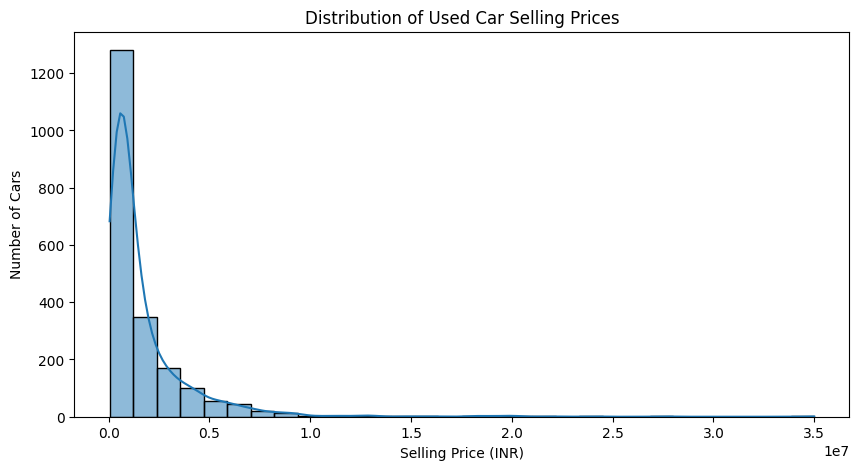

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of car selling prices
plt.figure(figsize=(10, 5))

sns.histplot(df["Price"], bins=30, kde=True)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (INR)")
plt.ylabel("Number of Cars")

plt.show()


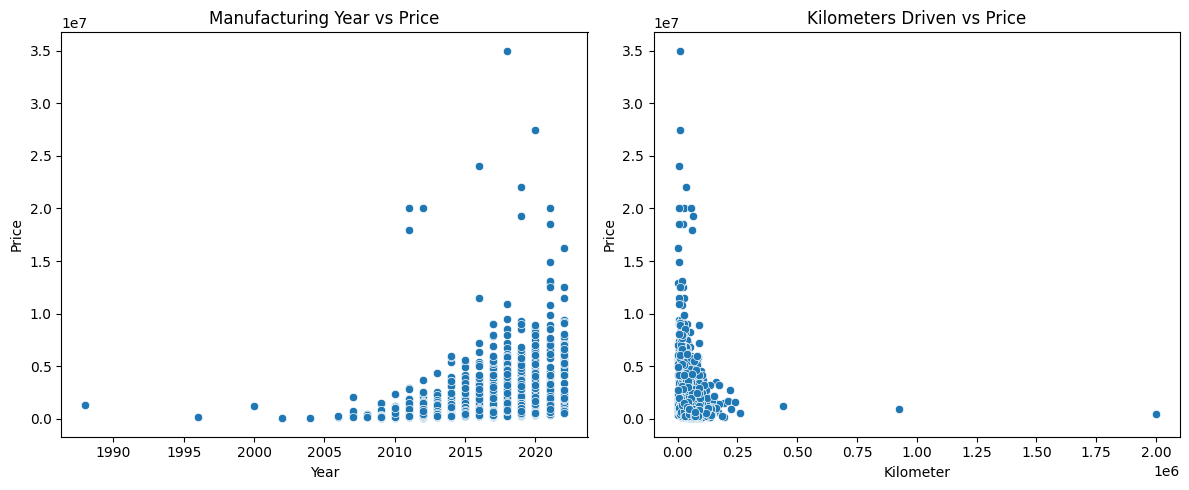

In [6]:

plt.figure(figsize=(12, 5))

# Year vs Price
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x="Year", y="Price")
plt.title("Manufacturing Year vs Price")

# Kilometer vs Price
plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x="Kilometer", y="Price")
plt.title("Kilometers Driven vs Price")

plt.tight_layout()
plt.show()


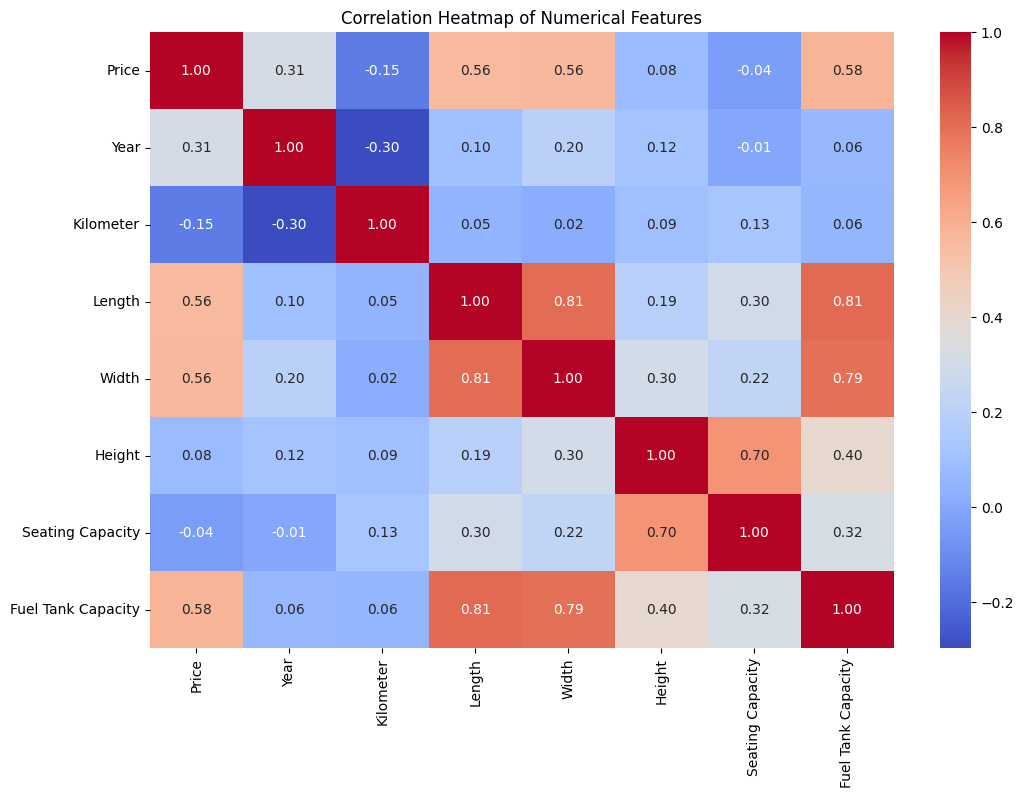

In [7]:

# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlations
correlation = numeric_df.corr()

# Display correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()


### Explanation – Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to understand the characteristics of the used car dataset.

The `info()` function was used to examine the data types and number of non-null values, while `isnull().sum()` identified missing values in individual columns.

The `describe()` function provided statistical summaries of numerical features, including their mean, standard deviation, minimum, and maximum values.

A histogram was created to examine the distribution of car selling prices.

Scatter plots were used to explore the relationships between selling price, manufacturing year, and kilometers driven.

Finally, a correlation heatmap was generated to examine linear relationships among numerical features.

These analyses help identify patterns and potential data quality issues before preprocessing and regression model development.

### Interpretation of Correlation Analysis

The correlation heatmap was used to examine relationships between numerical features and the target variable, Price.

Fuel Tank Capacity (0.58), Length (0.56), and Width (0.56) showed moderate positive correlations with selling price.

Year (0.31) showed a weaker positive relationship, suggesting that newer cars generally have higher selling prices.

Kilometer (-0.15) showed a weak negative correlation, indicating that cars with higher mileage tend to have slightly lower selling prices.

Strong correlations were also observed between Length and Width (0.81), and between Length and Fuel Tank Capacity (0.81).

These findings suggest that vehicle dimensions, fuel tank capacity, manufacturing year, and mileage may be useful features for predicting selling prices.

Correlation alone does not establish causation, and further modeling is required to evaluate their predictive importance.

## Step 3: Data Preprocessing

In [8]:

# Check missing values before preprocessing

print("Missing Values:")
print(df.isnull().sum())

print("\nColumn Data Types:")
print(df.dtypes)


Missing Values:
Make                    0
Model                   0
Price                   0
Year                    0
Kilometer               0
Fuel Type               0
Transmission            0
Location                0
Color                   0
Owner                   0
Seller Type             0
Engine                 80
Max Power              80
Max Torque             80
Drivetrain            136
Length                 64
Width                  64
Height                 64
Seating Capacity       64
Fuel Tank Capacity    113
dtype: int64

Column Data Types:
Make                   object
Model                  object
Price                   int64
Year                    int64
Kilometer               int64
Fuel Type              object
Transmission           object
Location               object
Color                  object
Owner                  object
Seller Type            object
Engine                 object
Max Power              object
Max Torque             object
Drivetrain 

### Step 3A: Feature Selection and Train-Test Split

In [9]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Price"])
y = df["Price"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (1647, 19)
Testing Features: (412, 19)
Training Target: (1647,)
Testing Target: (412,)


### Explanation – Train-Test Split

The dataset was divided into input features (`X`) and the target variable (`y`).

The target variable is Price, which represents the selling price of a used car.

The `train_test_split()` function was used to divide the dataset into 80% training data and 20% testing data.

The training set contains 1,647 records, while the testing set contains 412 records.

The training data will be used to fit the regression model, and the testing data will be used to evaluate its performance on unseen records.

The `random_state=42` parameter ensures that the same split can be reproduced.

Preprocessing transformations will be fitted using the training data to avoid data leakage.

In [10]:

# Examine technical specification columns

technical_columns = [
    "Engine",
    "Max Power",
    "Max Torque"
]

for column in technical_columns:
    print(f"\n{column} - Sample Values:")
    print(df[column].dropna().head(10).tolist())



Engine - Sample Values:
['1198 cc', '1248 cc', '1197 cc', '1197 cc', '2393 cc', '1373 cc', '1991 cc', '1995 cc', '1798 cc', '1461 cc']

Max Power - Sample Values:
['87 bhp @ 6000 rpm', '74 bhp @ 4000 rpm', '79 bhp @ 6000 rpm', '82 bhp @ 6000 rpm', '148 bhp @ 3400 rpm', '91 bhp @ 6000 rpm', '181 bhp @ 5500 rpm', '188 bhp @ 4000 rpm', '177 bhp @ 5100 rpm', '84 bhp @ 3750 rpm']

Max Torque - Sample Values:
['109 Nm @ 4500 rpm', '190 Nm @ 2000 rpm', '112.7619 Nm @ 4000 rpm', '113 Nm @ 4200 rpm', '343 Nm @ 1400 rpm', '130 Nm @ 4000 rpm', '300 Nm @ 1200 rpm', '400 Nm @ 1750 rpm', '250 Nm @ 1250 rpm', '200 Nm @ 1900 rpm']


### Step 3C: Converting Technical Specifications to Numerical Values

In [11]:

# Create copies of the training and testing data
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Extract numeric values from technical specifications
def extract_number(series):
    return pd.to_numeric(
        series.astype("string").str.extract(
            r"(\d+(?:\.\d+)?)", expand=False
        ),
        errors="coerce"
    )

# Convert Engine, Max Power and Max Torque
technical_columns = ["Engine", "Max Power", "Max Torque"]

for column in technical_columns:
    X_train_clean[column] = extract_number(X_train_clean[column])
    X_test_clean[column] = extract_number(X_test_clean[column])

# Display converted values
print("Converted Technical Specifications:")
display(X_train_clean[technical_columns].head(10))

# Check data types
print("\nData Types After Conversion:")
print(X_train_clean[technical_columns].dtypes)

# Check missing values
print("\nMissing Values After Conversion:")
print(X_train_clean[technical_columns].isnull().sum())


Converted Technical Specifications:


,Engine,Max Power,Max Torque
266,<NA>,<NA>,<NA>
1133,1995,184.0,350.0
1823,1997,138.0,320.0
1370,2925,326.0,700.0
67,2755,174.0,450.0
1009,1248,89.0,200.0
1763,1248,74.0,190.0
1970,1950,192.0,400.0
1313,2993,244.0,600.0
1537,1498,99.0,205.0



Data Types After Conversion:
Engine          Int64
Max Power     Float64
Max Torque    Float64
dtype: object

Missing Values After Conversion:
Engine        65
Max Power     65
Max Torque    65
dtype: int64


### Explanation – Technical Specification Conversion

The Engine, Max Power, and Max Torque columns originally contained numerical measurements combined with units such as cc, bhp, Nm, and rpm.

Regular expressions were used to extract the first numerical value from each entry. The extracted values were then converted into numeric data types using the Pandas `to_numeric()` function.

The conversion was applied separately to the training and testing datasets.

Missing or unrecognized values were converted to NaN so that they could be handled during the missing-value imputation stage.

This simplified conversion assumes that the first number represents the relevant specification and that the measurement units are consistent.

### Step 3D: Missing Value Handling, Encoding and Scaling

In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_columns = X_train_clean.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train_clean.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical Columns:", numeric_columns)
print("\nCategorical Columns:", categorical_columns)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train_clean)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test_clean)

print("\nPreprocessing Completed Successfully!")
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)


Numerical Columns: ['Year', 'Kilometer', 'Engine', 'Max Power', 'Max Torque', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']

Categorical Columns: ['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Drivetrain']

Preprocessing Completed Successfully!
Training Data Shape: (1647, 1068)
Testing Data Shape: (412, 1068)


### Explanation – Missing Value Handling, Encoding and Scaling

A preprocessing pipeline was created using Scikit-learn to prepare the dataset for regression modeling.

Numerical columns were processed using median imputation to replace missing values, followed by StandardScaler to standardize their values.

Categorical columns were processed using most-frequent-value imputation and one-hot encoding.

One-hot encoding converts categorical variables into binary numerical features without introducing an artificial ordering between categories.

ColumnTransformer was used to apply separate preprocessing operations to numerical and categorical features.

The preprocessing pipeline was fitted only on the training dataset and then applied to the testing dataset to prevent data leakage.

After preprocessing, the dataset is ready for regression model development.

## Step 4: Model Development – Linear Regression

**Objective:** Train a Linear Regression model using the preprocessed training dataset to predict used car selling prices.

In [15]:

from sklearn.linear_model import LinearRegression

# Initialize Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train_processed, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [16]:

# Predict prices for the testing dataset
y_pred = model.predict(X_test_processed)

# Compare actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("Actual vs Predicted Car Prices:")
display(results.head(10))


Actual vs Predicted Car Prices:


,Actual Price,Predicted Price
0,4800000,1.022038e+07
1,825000,8.549369e+05
2,695000,-3.018305e+06
3,950000,1.301203e+06
4,819999,6.776863e+05
5,310000,8.249681e+02
6,1000000,-1.750813e+06
7,1998999,-1.012408e+06
8,850000,1.612722e+07
9,3950000,2.007801e+06


### Explanation – Linear Regression Model Development

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

In this assignment, the target variable is the selling price of a used car.

A Linear Regression model was created using Scikit-learn's `LinearRegression()` class.

The model was trained using the preprocessed training dataset containing 1,647 records.

After training, the model was used to predict selling prices for 412 previously unseen test records.

The predicted prices were compared with the actual selling prices to understand the model's behavior.

The model's accuracy and prediction errors will be evaluated using regression performance metrics in the next step.

## Step 5: Model Evaluation

The performance of the Linear Regression model is evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared (R²).

In [17]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Evaluation")
print("----------------------------------")
print(f"Mean Absolute Error (MAE): ₹{mae:,.2f}")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")
print(f"R-squared (R²): {r2:.4f}")

# Count negative predictions
negative_count = np.sum(y_pred < 0)
print(f"\nNegative Price Predictions: {negative_count}")


Linear Regression Model Evaluation
----------------------------------
Mean Absolute Error (MAE): ₹1,830,918.60
Mean Squared Error (MSE): 17,983,456,801,820.48
Root Mean Squared Error (RMSE): ₹4,240,690.60
R-squared (R²): -1.5741

Negative Price Predictions: 63


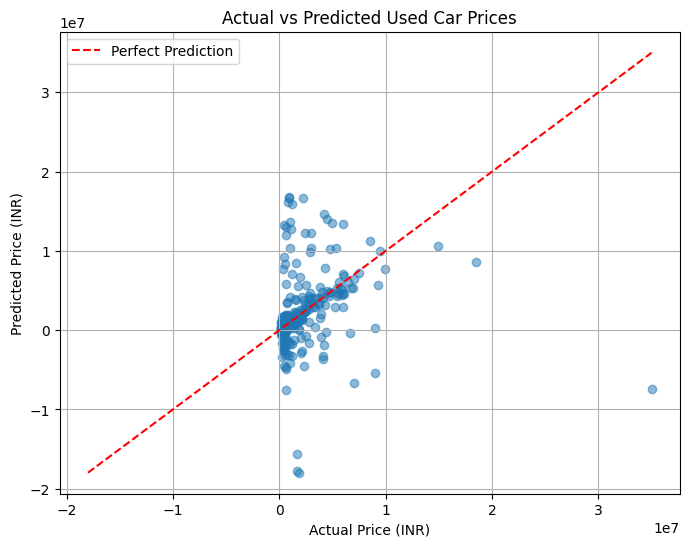

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (INR)")
plt.ylabel("Predicted Price (INR)")
plt.title("Actual vs Predicted Used Car Prices")
plt.legend()
plt.grid(True)
plt.show()


### Explanation – Model Evaluation

The Linear Regression model was evaluated using MAE, MSE, RMSE, and R-squared.

MAE measures the average absolute prediction error, while MSE gives greater weight to large errors. RMSE expresses prediction error in the same units as selling price.

R-squared measures the model's performance relative to predicting the average selling price.

An actual versus predicted price scatter plot was created to visualize prediction accuracy.

Some predictions were negative or substantially different from actual prices, indicating that the initial Linear Regression model may require improvement.

## Step 6: Model Improvement Using Ridge Regression

Ridge Regression is used to improve model stability by applying L2 regularization.

In [19]:

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Create and train Ridge Regression model
ridge_model = Ridge(alpha=100.0)

ridge_model.fit(X_train_processed, y_train)

# Predict prices
ridge_pred = ridge_model.predict(X_test_processed)

# Evaluate Ridge Regression
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression Model Evaluation")
print("---------------------------------")
print(f"MAE: ₹{ridge_mae:,.2f}")
print(f"MSE: {ridge_mse:,.2f}")
print(f"RMSE: ₹{ridge_rmse:,.2f}")
print(f"R-squared (R²): {ridge_r2:.4f}")
print(f"Negative Price Predictions: {(ridge_pred < 0).sum()}")

# Compare the two models
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Linear Regression": [mae, rmse, r2],
    "Ridge Regression": [ridge_mae, ridge_rmse, ridge_r2]
})

print("\nModel Comparison:")
display(comparison)


Ridge Regression Model Evaluation
---------------------------------
MAE: ₹718,891.52
MSE: 2,241,179,275,237.12
RMSE: ₹1,497,056.87
R-squared (R²): 0.6792
Negative Price Predictions: 48

Model Comparison:


,Metric,Linear Regression,Ridge Regression
0,MAE,1.830919e+06,7.188915e+05
1,RMSE,4.240691e+06,1.497057e+06
2,R²,-1.574110e+00,6.792029e-01


### Explanation – Model Improvement

The initial Linear Regression model produced an R² score of -1.5741 and several negative price predictions, indicating poor performance on the testing dataset.

Ridge Regression was introduced as an alternative model because it applies L2 regularization, which helps control large regression coefficients and can improve model stability.

The Ridge Regression model was trained using the same preprocessed training dataset and evaluated using the same testing dataset.

The performance of both models was compared using MAE, RMSE, and R² to determine whether regularization improved prediction accuracy.

An alpha value of 100 was used as an initial regularization setting. Further tuning may improve performance.

## Step 7: Visualization of Ridge Regression Predictions

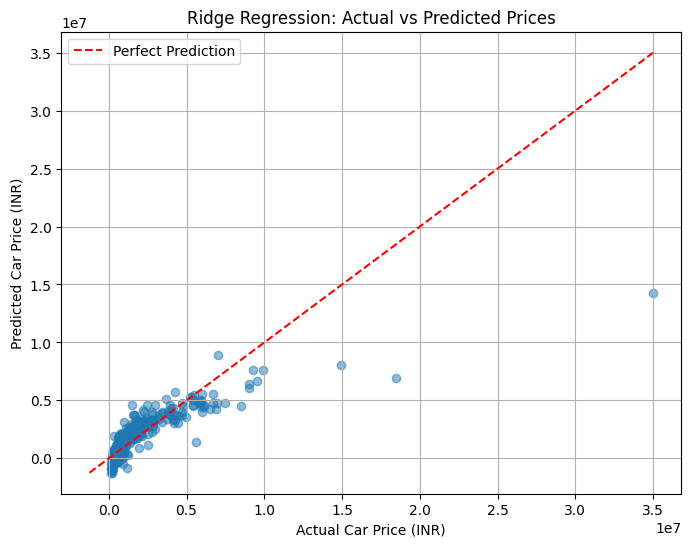

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, ridge_pred, alpha=0.5)

# Reference line for perfect predictions
minimum = min(y_test.min(), ridge_pred.min())
maximum = max(y_test.max(), ridge_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Car Price (INR)")
plt.ylabel("Predicted Car Price (INR)")
plt.title("Ridge Regression: Actual vs Predicted Prices")
plt.legend()
plt.grid(True)
plt.show()


### Interpretation of Model Performance

Two regression models were trained and evaluated to predict used car selling prices.

The initial Linear Regression model performed poorly, producing an R² score of -1.5741 and an RMSE of ₹42,40,690.60.

Ridge Regression improved the results significantly, achieving an R² score of 0.6792 and reducing the RMSE to ₹14,97,056.87.

The Ridge model also reduced the Mean Absolute Error from ₹18,30,918.60 to ₹7,18,891.52.

These results demonstrate that L2 regularization helped improve model stability and predictive performance.

However, the Ridge model still generated some negative price predictions, indicating that further improvements are possible.

Based on the evaluation metrics, Ridge Regression was selected as the better-performing model in this experiment.

### Interpretation of Ridge Regression Visualization

The scatter plot compares actual used car selling prices with prices predicted by the Ridge Regression model.

The red dashed diagonal line represents perfect predictions, where actual and predicted prices are equal.

Most observations are concentrated in the lower price range, with several predictions appearing close to the reference line.

However, some high-priced vehicles have predicted prices considerably below their actual selling prices, indicating that the model struggles with certain expensive vehicles.

The Ridge Regression model achieved an R² score of 0.6792, demonstrating an improvement over the initial Linear Regression model.

Although Ridge Regression performed better, further improvements could be achieved through feature engineering, hyperparameter tuning, and alternative regression algorithms.

## Conclusion

This assignment demonstrated the application of supervised machine learning regression techniques to predict used car selling prices.

The dataset contained **2,059 car records and 20 columns**, including vehicle specifications, manufacturing year, mileage, and selling price.

The following stages were completed:

1. **Data Exploration:** Examined the dataset, identified missing values, and visualized relationships between vehicle characteristics and selling prices.

2. **Data Preprocessing:** Converted technical specifications into numerical values, handled missing data using imputation, encoded categorical variables, and standardized numerical features.

3. **Model Development:** Divided the dataset into 80% training and 20% testing data and trained a Linear Regression model.

4. **Model Evaluation:** Evaluated prediction performance using MAE, MSE, RMSE, and R².

5. **Model Improvement:** Applied Ridge Regression with L2 regularization to improve model stability and prediction accuracy.

### Final Results

| Evaluation Metric | Linear Regression | Ridge Regression |
|---|---:|---:|
| MAE | ₹18,30,918.60 | ₹7,18,891.52 |
| RMSE | ₹42,40,690.60 | ₹14,97,056.87 |
| R² | -1.5741 | 0.6792 |

Ridge Regression performed better than the initial Linear Regression model, achieving an R² score of approximately **0.68**.

The results indicate that regularization can improve prediction performance when working with a large number of encoded features.

However, some prediction errors remain, particularly for expensive vehicles. Further improvements could involve hyperparameter tuning, feature engineering, and additional model comparisons.

Overall, the assignment demonstrates the complete machine learning workflow, from dataset exploration and preprocessing to model training, evaluation, and interpretation.